In [1]:
# Install libraries for loading and exploring datasets
%pip install -q datasets huggingface_hub pandas pyarrow matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
# Import libraries for dataset loading and analysis
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from huggingface_hub import HfApi

print("Libraries imported successfully!")

c:\Users\ragha\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported successfully!


In [2]:
# Record the dataset revision for reproducibility
api = HfApi()

nf_revision = api.dataset_info("BeIR/nfcorpus").sha
print("NFCorpus revision:", nf_revision)

# Load the NFCorpus document collection
nfcorpus = load_dataset(
    "BeIR/nfcorpus",
    "corpus",
    revision=nf_revision
)

print(nfcorpus)

NFCorpus revision: b5026a0e96e8a7ac4f95f482a596389289d46269


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Generating corpus split: 100%|██████████| 3633/3633 [00:00<00:00, 45289.58 examples/s]

DatasetDict({
    corpus: Dataset({
        features: ['_id', 'title', 'text'],
        num_rows: 3633
    })
})


In [3]:
# Inspect the dataset structure
print("Available splits:", list(nfcorpus.keys()))

nf_split = next(iter(nfcorpus.keys()))
nf_data = nfcorpus[nf_split]

print("Total documents:", len(nf_data))
print("Columns:", nf_data.column_names)

# Look at one example document
print(nf_data[0])

Available splits: ['corpus']
Total documents: 3633
Columns: ['_id', 'title', 'text']
{'_id': 'MED-10', 'title': 'Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland', 'text': 'Recent studies have suggested that statins, an established drug group in the prevention of cardiovascular mortality, could delay or prevent breast cancer recurrence but the effect on disease-specific mortality remains unclear. We evaluated risk of breast cancer death among statin users in a population-based cohort of breast cancer patients. The study cohort included all newly diagnosed breast cancer patients in Finland during 1995–2003 (31,236 cases), identified from the Finnish Cancer Registry. Information on statin use before and after the diagnosis was obtained from a national prescription database. We used the Cox proportional hazards regression method to estimate mortality among statin users with statin use as time-dependent variable. A total of 4,151 participants had used statins. 

In [4]:
# Convert NFCorpus into our shared document format
nf_docs = []

for row in nf_data:
    nf_docs.append({
        "doc_id": str(row["_id"]),
        "title": row["title"] or "",
        "text": row["text"] or "",
        "source": "nfcorpus"
    })

nf_df = pd.DataFrame(nf_docs)

print("DataFrame shape:", nf_df.shape)
print("Unique document IDs:", nf_df["doc_id"].nunique())
print("Missing document texts:", (nf_df["text"].str.strip() == "").sum())

display(nf_df.head())

DataFrame shape: (3633, 4)
Unique document IDs: 3633
Missing document texts: 0


,doc_id,title,text,source
0,MED-10,Statin Use and Breast Cancer Survival: A Natio...,"Recent studies have suggested that statins, an...",nfcorpus
1,MED-14,Statin use after diagnosis of breast cancer an...,BACKGROUND: Preclinical studies have shown tha...,nfcorpus
2,MED-118,Alkylphenols in human milk and their relations...,The aims of this study were to determine the c...,nfcorpus
3,MED-301,Methylmercury: A Potential Environmental Risk ...,Epilepsy or seizure disorder is one of the mos...,nfcorpus
4,MED-306,Sensitivity of Continuous Performance Test (CP...,Hit Reaction Time latencies (HRT) in the Conti...,nfcorpus


In [5]:
# Load the labeled PubMedQA dataset
pubmed_revision = api.dataset_info("qiaojin/PubMedQA").sha

print("PubMedQA revision:", pubmed_revision)

pubmedqa = load_dataset(
    "qiaojin/PubMedQA",
    "pqa_labeled",
    revision=pubmed_revision
)

print(pubmedqa)

PubMedQA revision: 9001f2853fb87cab8d220904e0de81ac6973b318


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Generating train split: 100%|██████████| 1000/1000 [00:00<00:00, 71545.85 examples/s]

DatasetDict({
    train: Dataset({
        features: ['pubid', 'question', 'context', 'long_answer', 'final_decision'],
        num_rows: 1000
    })
})


In [6]:
# Check dataset structure before processing
print("Available splits:", list(pubmedqa.keys()))

pubmed_split = next(iter(pubmedqa.keys()))
pubmed_data = pubmedqa[pubmed_split]

print("Total records:", len(pubmed_data))
print("Columns:", pubmed_data.column_names)

# Print one example to understand its structure
print(pubmed_data[0])

Available splits: ['train']
Total records: 1000
Columns: ['pubid', 'question', 'context', 'long_answer', 'final_decision']
{'pubid': 21645374, 'question': 'Do mitochondria play a role in remodelling lace plant leaves during programmed cell death?', 'context': {'contexts': ['Programmed cell death (PCD) is the regulated death of cells within an organism. The lace plant (Aponogeton madagascariensis) produces perforations in its leaves through PCD. The leaves of the plant consist of a latticework of longitudinal and transverse veins enclosing areoles. PCD occurs in the cells at the center of these areoles and progresses outwards, stopping approximately five cells from the vasculature. The role of mitochondria during PCD has been recognized in animals; however, it has been less studied during PCD in plants.', 'The following paper elucidates the role of mitochondrial dynamics during developmentally regulated PCD in vivo in A. madagascariensis. A single areole within a window stage leaf (PCD 

In [7]:
# Examine how PubMedQA stores research abstracts
sample = pubmed_data[0]

print("Document ID:", sample["pubid"])
print("Question:", sample["question"])
print("Context type:", type(sample["context"]))

print("\nContext fields:")
print(sample["context"].keys())

print("\nContext example:")
print(sample["context"])

Document ID: 21645374
Question: Do mitochondria play a role in remodelling lace plant leaves during programmed cell death?
Context type: <class 'dict'>

Context fields:
dict_keys(['contexts', 'labels', 'meshes', 'reasoning_required_pred', 'reasoning_free_pred'])

Context example:
{'contexts': ['Programmed cell death (PCD) is the regulated death of cells within an organism. The lace plant (Aponogeton madagascariensis) produces perforations in its leaves through PCD. The leaves of the plant consist of a latticework of longitudinal and transverse veins enclosing areoles. PCD occurs in the cells at the center of these areoles and progresses outwards, stopping approximately five cells from the vasculature. The role of mitochondria during PCD has been recognized in animals; however, it has been less studied during PCD in plants.', 'The following paper elucidates the role of mitochondrial dynamics during developmentally regulated PCD in vivo in A. madagascariensis. A single areole within a wi

In [8]:
# Convert PubMedQA abstracts into our shared document format
pubmed_docs = []

for row in pubmed_data:
    context = row["context"]
    passages = context.get("contexts") or []

    pubmed_docs.append({
        "doc_id": str(row["pubid"]),
        "title": row["question"],
        "text": "\n\n".join(passages),
        "source": "pubmedqa",
        "sections": passages,
        "section_labels": context.get("labels") or []
    })

pubmed_df = pd.DataFrame(pubmed_docs)

print("DataFrame shape:", pubmed_df.shape)
print("Unique document IDs:", pubmed_df["doc_id"].nunique())
print("Missing abstracts:", (pubmed_df["text"].str.strip() == "").sum())

display(pubmed_df.head())

DataFrame shape: (1000, 6)
Unique document IDs: 1000
Missing abstracts: 0


,doc_id,title,text,source,sections,section_labels
0,21645374,Do mitochondria play a role in remodelling lac...,Programmed cell death (PCD) is the regulated d...,pubmedqa,[Programmed cell death (PCD) is the regulated ...,"[BACKGROUND, RESULTS]"
1,16418930,Landolt C and snellen e acuity: differences in...,Assessment of visual acuity depends on the opt...,pubmedqa,[Assessment of visual acuity depends on the op...,"[BACKGROUND, PATIENTS AND METHODS, RESULTS]"
2,9488747,"Syncope during bathing in infants, a pediatric...",Apparent life-threatening events in infants ar...,pubmedqa,[Apparent life-threatening events in infants a...,"[BACKGROUND, CASE REPORTS]"
3,17208539,Are the long-term results of the transanal pul...,The transanal endorectal pull-through (TERPT) ...,pubmedqa,[The transanal endorectal pull-through (TERPT)...,"[PURPOSE, METHODS, RESULTS]"
4,10808977,Can tailored interventions increase mammograph...,Telephone counseling and tailored print commun...,pubmedqa,[Telephone counseling and tailored print commu...,"[BACKGROUND, DESIGN, PARTICIPANTS, INTERVENTIO..."


In [9]:
# Calculate word counts for both datasets
nf_df["word_count"] = nf_df["text"].apply(
    lambda text: len(text.split())
)

pubmed_df["word_count"] = pubmed_df["text"].apply(
    lambda text: len(text.split())
)

print("NFCorpus document lengths:")
display(nf_df["word_count"].describe())

print("\nPubMedQA abstract lengths:")
display(pubmed_df["word_count"].describe())

NFCorpus document lengths:


count    3633.000000
mean      220.978805
std        82.137592
min        13.000000
25%       173.000000
50%       224.000000
75%       258.000000
max      1460.000000
Name: word_count, dtype: float64


PubMedQA abstract lengths:


count    1000.000000
mean      200.207000
std        51.846429
min        49.000000
25%       166.750000
50%       200.500000
75%       228.000000
max       398.000000
Name: word_count, dtype: float64

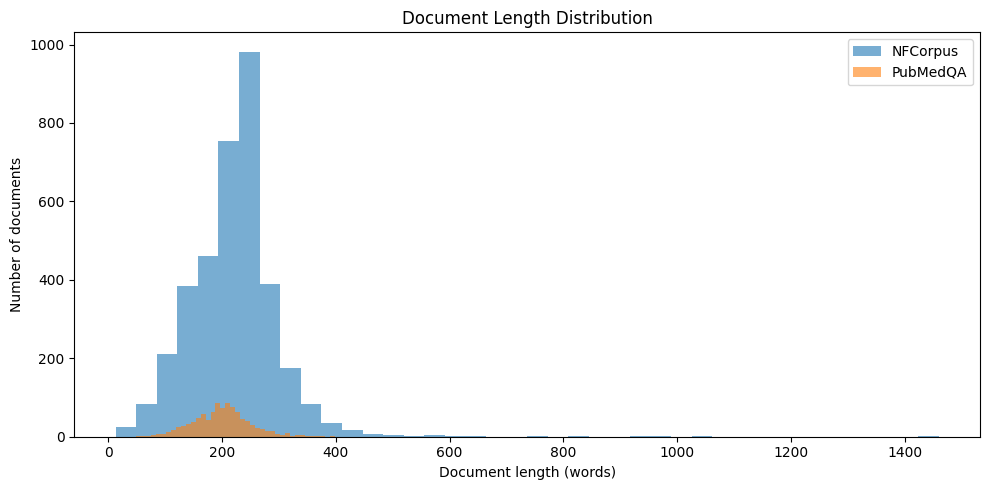

In [10]:
# Visualize document lengths for both datasets
plt.figure(figsize=(10, 5))

plt.hist(
    nf_df["word_count"],
    bins=40,
    alpha=0.6,
    label="NFCorpus"
)

plt.hist(
    pubmed_df["word_count"],
    bins=40,
    alpha=0.6,
    label="PubMedQA"
)

plt.xlabel("Document length (words)")
plt.ylabel("Number of documents")
plt.title("Document Length Distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# Compare document length statistics
summary = pd.DataFrame([
    {
        "Dataset": "NFCorpus",
        "Documents": len(nf_df),
        "Average Words": nf_df["word_count"].mean(),
        "Median Words": nf_df["word_count"].median(),
        "Max Words": nf_df["word_count"].max()
    },
    {
        "Dataset": "PubMedQA",
        "Documents": len(pubmed_df),
        "Average Words": pubmed_df["word_count"].mean(),
        "Median Words": pubmed_df["word_count"].median(),
        "Max Words": pubmed_df["word_count"].max()
    }
])

display(summary.round(2))

,Dataset,Documents,Average Words,Median Words,Max Words
0,NFCorpus,3633,220.98,224.0,1460
1,PubMedQA,1000,200.21,200.5,398


### Part 1 — Dataset Exploration Findings

- Loaded 3,633 NFCorpus documents and 1,000 labeled PubMedQA abstracts.
- Preserved original document IDs, titles, and text.
- Preserved PubMedQA abstract sections for future adaptive chunking.
- NFCorpus documents average 220.98 words, compared with 200.21 for PubMedQA.
- NFCorpus has a wider document-length distribution, including outliers up to 1,460 words.
- These findings motivate comparing fixed-size and structure-aware chunking.
- Actual token counts will be examined before finalizing chunk-size parameters.